# 09 - RFM Analysis: Segmenting Customers by Recency, Frequency and Monetary Value
**Topic:** Clustering / customer segmentation  |  **Reference:** "A Guide to RFM Analysis using Python" (amanxai.com, Aug 2025)

**Question.** Which customers are the most valuable and which are drifting away, judged from when, how often and how much they buy?

**Reference method:** compute R, F, M per customer, score each 1-4 by quartiles, concatenate the scores into segments.
**What I check that it does not:** (1) whether the data support quartile scoring at all (here 95% of customers bought once, so "frequency quartiles" break), (2) a rank-based scoring that handles ties, (3) whether k-means finds anything the rules do not (with a shuffled-data null), and (4) the most important test: **do the RFM scores predict what customers do next?**

## 1. Libraries and data

In [1]:
import warnings, os, json, joblib
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, adjusted_rand_score
sns.set_theme(style="whitegrid", context="notebook")
os.makedirs("model", exist_ok=True)
df = pd.read_csv("../_data/rfm_data.csv"); df["PurchaseDate"] = pd.to_datetime(df["PurchaseDate"])
print(df.shape, "| customers:", df.CustomerID.nunique(), "| dates:", df.PurchaseDate.min().date(), "to", df.PurchaseDate.max().date(), "| duplicate rows:", int(df.duplicated().sum())); df.head()

(1000, 6) | customers: 946 | dates: 2023-04-11 to 2023-06-10 | duplicate rows: 0


,CustomerID,PurchaseDate,TransactionAmount,ProductInformation,OrderID,Location
0,8814,2023-04-11,943.31,Product C,890075,Tokyo
1,2188,2023-04-11,463.70,Product A,176819,London
2,4608,2023-04-11,80.28,Product A,340062,New York
3,2559,2023-04-11,221.29,Product A,239145,London
4,9482,2023-04-11,739.56,Product A,194545,Paris


## 2. Look at the data first

purchases per customer: {1: 895, 2: 48, 3: 3} -> 94.6% bought exactly once
order id unique: True | amount range 12-999, mean 514, median 524


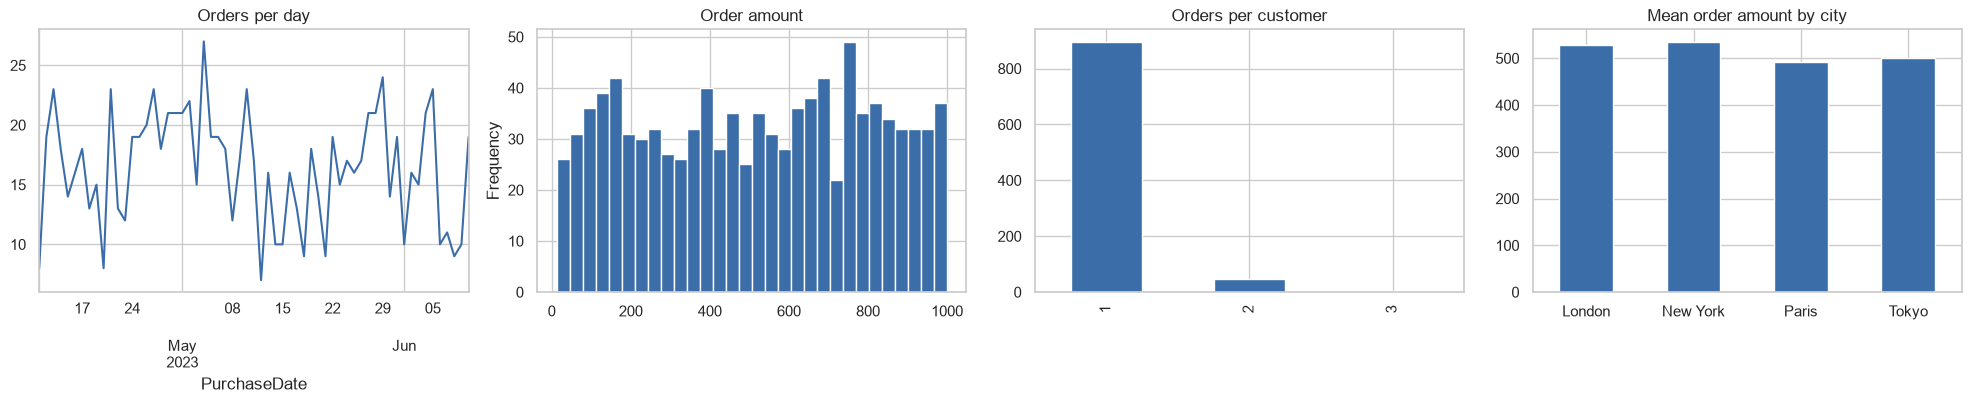

In [2]:
per = df.groupby("CustomerID").agg(n=("OrderID", "size"), spend=("TransactionAmount", "sum"))
print("purchases per customer:", per.n.value_counts().sort_index().to_dict(), "-> %.1f%% bought exactly once" % ((per.n == 1).mean() * 100))
print("order id unique:", df.OrderID.is_unique, "| amount range %.0f-%.0f, mean %.0f, median %.0f" % (df.TransactionAmount.min(), df.TransactionAmount.max(), df.TransactionAmount.mean(), df.TransactionAmount.median()))
fig, ax = plt.subplots(1, 4, figsize=(20, 4.2))
df.groupby("PurchaseDate").size().plot(ax=ax[0], color="#3b6ea8"); ax[0].set_title("Orders per day")
df.TransactionAmount.plot.hist(bins=30, ax=ax[1], color="#3b6ea8"); ax[1].set_title("Order amount")
per.n.value_counts().sort_index().plot.bar(ax=ax[2], color="#3b6ea8"); ax[2].set_title("Orders per customer"); ax[2].set_xlabel("")
df.groupby("Location").TransactionAmount.mean().plot.bar(ax=ax[3], color="#3b6ea8"); ax[3].set_title("Mean order amount by city"); ax[3].set_xlabel(""); ax[3].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

**Reading it.** 1,000 orders from 946 customers over 61 days (2023-04-11 to 06-10). **94.6% of customers (895) ordered exactly once**; 48 ordered twice and 3 three times. Order amounts run from 12 to 999 with mean 514 and median 524, i.e. spread evenly across the whole range (the shape of a uniform distribution, not of real basket values, which usually skew toward small orders). Order IDs are all unique. In other words this is a *one-time-buyer* data set seen through a two-month window, and "frequency" will carry little information. (The source does not say how the file was produced; I infer a generated sample from the flat amount distribution.)

## 3. Compute R, F and M
Snapshot date = last date + 1 day. **Recency** = days since the customer's last order; **Frequency** = number of orders; **Monetary** = total spend.

In [3]:
snap = df.PurchaseDate.max() + pd.Timedelta(days=1)
rfm = df.groupby("CustomerID").agg(R=("PurchaseDate", lambda d: (snap - d.max()).days), F=("OrderID", "count"), M=("TransactionAmount", "sum"))
print(rfm.describe().round(1).T.to_string())
print("\ncorrelations (Spearman):\n", rfm.corr(method="spearman").round(2).to_string())

   count   mean    std   min    25%    50%    75%     max
R  946.0   31.0   17.3   1.0   15.0   32.0   45.0    61.0
F  946.0    1.1    0.2   1.0    1.0    1.0    1.0     3.0
M  946.0  543.0  324.4  12.1  266.6  542.9  782.7  2379.4

correlations (Spearman):
       R     F     M
R  1.00 -0.10 -0.03
F -0.10  1.00  0.27
M -0.03  0.27  1.00


## 4. The reference's quartile scoring, and why it breaks
It cuts each variable at its 25th / 50th / 75th percentiles. For Frequency those percentiles are all equal to 1, so the cut-offs have no room to separate anyone.

In [4]:
q = rfm.quantile([.25, .5, .75]); print("quartile cut-offs:\n", q.round(1).to_string())
def score_q(v, qs, higher_better=True):
    s = 1 + (v > qs.iloc[0]) + (v > qs.iloc[1]) + (v > qs.iloc[2]); return s if higher_better else 5 - s
ref = pd.DataFrame({"R": score_q(rfm.R, q.R, False), "F": score_q(rfm.F, q.F), "M": score_q(rfm.M, q.M)})
print("\nreference-style scores, share of customers:"); print(ref.apply(lambda c: c.value_counts(normalize=True).sort_index().round(3)).fillna(0).to_string())

quartile cut-offs:
          R    F      M
0.25  15.0  1.0  266.6
0.50  32.0  1.0  542.9
0.75  45.0  1.0  782.7

reference-style scores, share of customers:
       R      F      M
1  0.244  0.946  0.251
2  0.248  0.000  0.249
3  0.254  0.000  0.249
4  0.254  0.054  0.251


**Reading it.** The three quartile cut-offs for Frequency are all 1, so the reference's scoring puts **94.6% of customers at score 1, 5.4% at score 4 and nobody at 2 or 3**. The F score is effectively a two-valued flag, so three-digit RFM codes like "444" or "114" are mostly determined by R and M alone. Quartiles only work when the variable has enough distinct values; always look at the cut-offs.

## 5. A scoring that handles ties
* **R and M**: quintile scores 1-5 from ranks (ties broken by order), so each score has about 20% of customers.
* **F**: business-defined bins because the data have only 1, 2 or 3 orders: **1 = one order, 2 = two orders, 3 = three or more**.
Segments use R and the repeat-buyer flag together with M, in the spirit of the standard RFM grid.

In [5]:
rfm["r"] = pd.qcut(rfm.R.rank(method="first", ascending=False), 5, labels=[1, 2, 3, 4, 5]).astype(int)    # 5 = most recent
rfm["m"] = pd.qcut(rfm.M.rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["f"] = np.where(rfm.F >= 3, 3, rfm.F)
def segment(row):
    r, f, m = row.r, row.f, row.m
    if f >= 2 and r >= 4: return "Champions (repeat, recent)"
    if f >= 2: return "Repeat, drifting"
    if r >= 4 and m >= 4: return "New big spenders"
    if r >= 4: return "New customers"
    if m >= 4: return "At risk big spenders (one order, not recent)"
    return "Hibernating (one order, low spend, not recent)"
rfm["segment"] = rfm.apply(segment, axis=1)
seg = rfm.groupby("segment").agg(customers=("R", "size"), share_customers=("R", lambda s: len(s) / len(rfm)), mean_recency_days=("R", "mean"), mean_spend=("M", "mean"), revenue=("M", "sum"))
seg["share_revenue"] = seg.revenue / seg.revenue.sum(); print(seg.sort_values("revenue", ascending=False).round(2).to_string())

                                                customers  share_customers  mean_recency_days  mean_spend    revenue  share_revenue
segment                                                                                                                            
At risk big spenders (one order, not recent)          204             0.22              42.37      816.99  166666.70           0.32
Hibernating (one order, low spend, not recent)        339             0.36              44.04      338.70  114817.97           0.22
New big spenders                                      133             0.14              13.04      820.06  109067.68           0.21
New customers                                         219             0.23              12.76      312.46   68429.18           0.13
Champions (repeat, recent)                             26             0.03              11.04     1071.38   27855.90           0.05
Repeat, drifting                                       25             0.03  

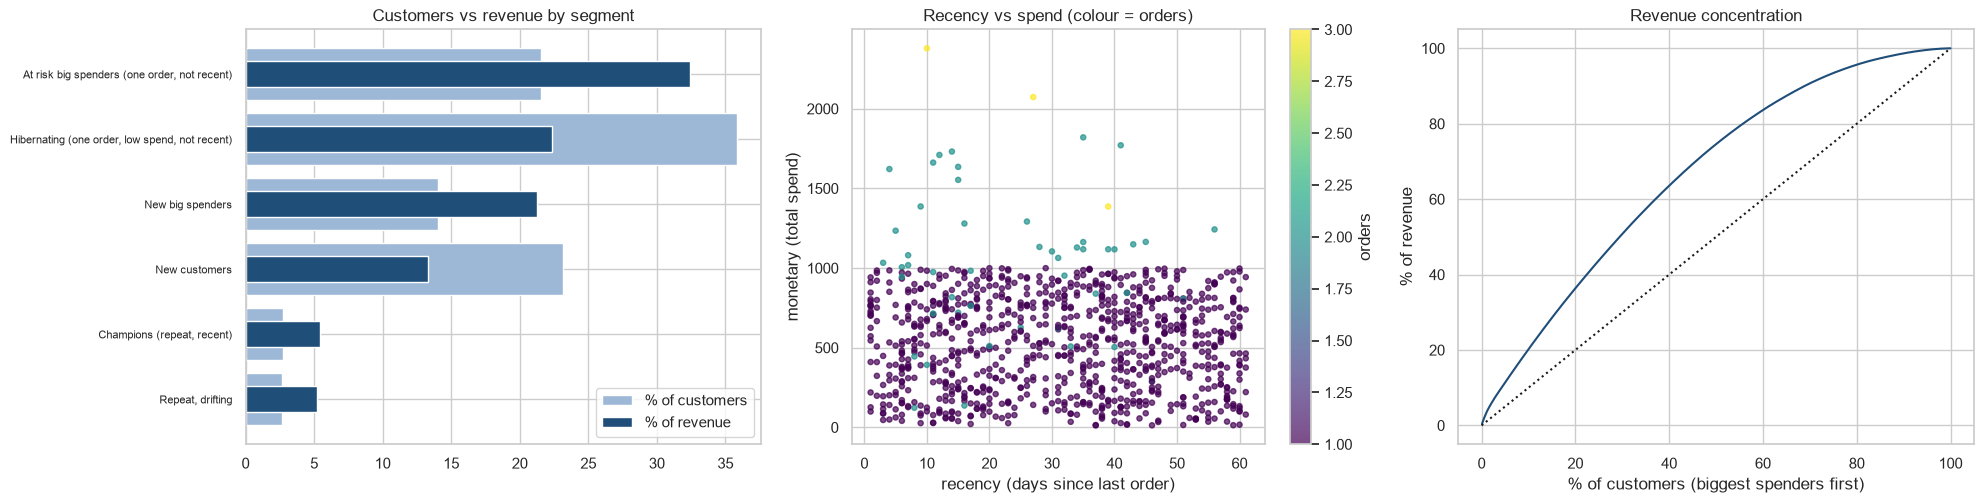

top 20% of customers account for 36% of revenue (a Pareto-like 80/20 pattern would be about 80%)


In [6]:
fig, ax = plt.subplots(1, 3, figsize=(20, 5.2))
o = seg.sort_values("revenue")
ax[0].barh(o.index, o.share_customers * 100, color="#9db8d6", label="% of customers"); ax[0].barh(o.index, o.share_revenue * 100, height=.4, color="#1f4e79", label="% of revenue"); ax[0].legend(); ax[0].set_title("Customers vs revenue by segment"); ax[0].tick_params(axis="y", labelsize=8)
sc = ax[1].scatter(rfm.R, rfm.M, c=rfm.F, cmap="viridis", s=14, alpha=.7); plt.colorbar(sc, ax=ax[1], label="orders"); ax[1].set_xlabel("recency (days since last order)"); ax[1].set_ylabel("monetary (total spend)"); ax[1].set_title("Recency vs spend (colour = orders)")
cs = rfm.sort_values("M", ascending=False).M.cumsum() / rfm.M.sum(); ax[2].plot(np.arange(1, len(cs) + 1) / len(cs) * 100, cs * 100, color="#1f4e79"); ax[2].plot([0, 100], [0, 100], "k:"); ax[2].set_xlabel("% of customers (biggest spenders first)"); ax[2].set_ylabel("% of revenue"); ax[2].set_title("Revenue concentration")
plt.tight_layout(); plt.show()
print("top 20%% of customers account for %.0f%% of revenue (a Pareto-like 80/20 pattern would be about 80%%)" % (float(cs.iloc[int(.2 * len(cs)) - 1]) * 100))

**Reading it.**
* Because frequency is almost always 1, the useful split is "repeat vs one-time" plus recency and spend. Only **51 customers (5.4%) are repeat buyers**; the 26 recent ones are the "Champions" and they account for just 5% of revenue.
* The largest revenue pool is not in any "new" segment: **204 one-order, big-spending customers who have not been back for a while** (mean 42 days since their order) produce 32% of revenue, more than any other segment. The natural business action is a win-back offer for this group.
* Revenue is **not** concentrated: the top 20% of customers account for 36% of revenue (a Pareto pattern would be about 80%), which is what evenly spread order values give you.
* These segments are *definitions* (rule cut-offs chosen by me), not discoveries; their names say what the rule means, not that customers behave that way.

## 6. Does k-means find anything the rules do not? Real data vs a shuffled null
k-means on standardised log R, F, M for k = 2..8, silhouette against 30 copies where each column is shuffled independently (no relationships).

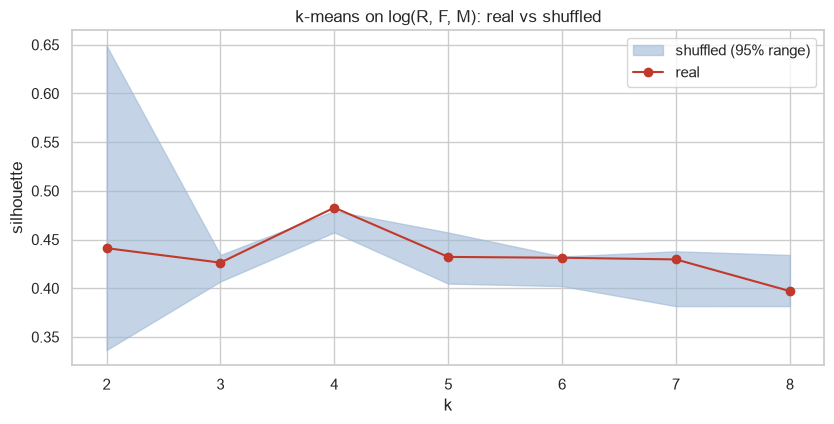

real best silhouette 0.483 (k=4) | shuffled best: mean 0.576, 95% range 0.464-0.649
agreement between k=4 k-means and my rule segments (ARI): 0.24


In [7]:
Z = StandardScaler().fit_transform(np.log1p(rfm[["R", "F", "M"]]))
ks = list(range(2, 9))
def sc_curve(Zm, seed=0): return [silhouette_score(Zm, KMeans(k, n_init=3, random_state=seed).fit_predict(Zm)) for k in ks]
real = sc_curve(Z); nulls = []
for s in range(30):
    r = np.random.RandomState(s); Zn = np.c_[[r.permutation(Z[:, j]) for j in range(3)]].T; nulls.append(sc_curve(Zn, s))
nulls = np.array(nulls)
fig, ax = plt.subplots(figsize=(8.5, 4.4)); ax.fill_between(ks, np.percentile(nulls, 2.5, 0), np.percentile(nulls, 97.5, 0), color="#9db8d6", alpha=.6, label="shuffled (95% range)"); ax.plot(ks, real, "o-", color="#c0392b", label="real"); ax.set_xlabel("k"); ax.set_ylabel("silhouette"); ax.legend(); ax.set_title("k-means on log(R, F, M): real vs shuffled"); plt.tight_layout(); plt.show()
km = KMeans(4, n_init=10, random_state=0).fit(Z)
print("real best silhouette %.3f (k=%d) | shuffled best: mean %.3f, 95%% range %.3f-%.3f" % (max(real), ks[int(np.argmax(real))], nulls.max(1).mean(), *np.percentile(nulls.max(1), [2.5, 97.5])))
print("agreement between k=4 k-means and my rule segments (ARI): %.2f" % adjusted_rand_score(km.labels_, rfm.segment))

**Reading it.** On log R/F/M, k-means has a best silhouette of 0.48 at k = 4, but shuffled data with the same marginals reach 0.58 on average (95% range 0.46-0.65): **the real value is not better than noise**, so k-means is not discovering natural customer groups beyond the marginal distributions (the high silhouettes come mostly from Frequency being 1, 2 or 3, which makes clean-looking vertical bands). Its k = 4 clusters agree only weakly with my rule segments (adjusted Rand index 0.24). The rule-based RFM segmentation is a transparent ranking convention; the k-means version adds nothing here.

## 7. The decisive test: do RFM scores predict future behaviour?
Cut time at the middle: build R/F/M using only orders **up to 2023-05-10**, and look at what those customers do **after** (2023-05-11 to 06-10): did they order again, and how much did they spend? If RFM scores mean anything, "good" segments should do better afterwards.

customers with a purchase before the cut: 513 | came back afterwards: 28 (5.5%)

return rate by recency quartile (4 = most recent)
   mean  sum  size  ci95
r                       
1   4.7    6   129   3.6
2   4.7    6   128   3.7
3   3.9    5   128   3.4
4   8.6   11   128   4.9

return rate by spend quartile (4 = biggest)
   mean  sum  size  ci95
m                       
1   5.4    7   129   3.9
2   6.2    8   128   4.2
3   2.3    3   128   2.6
4   7.8   10   128   4.6

Spearman(recency days, future spend) = -0.046 (p = 0.30) | Spearman(past spend, future spend) = -0.002 (p = 0.97)


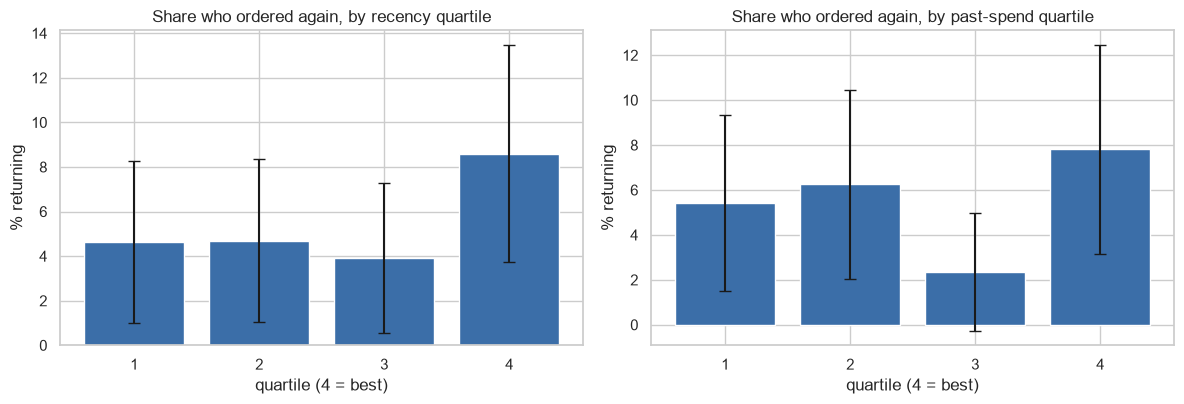

In [8]:
cut = pd.Timestamp("2023-05-11")
past, fut = df[df.PurchaseDate < cut], df[df.PurchaseDate >= cut]
snap2 = cut
p = past.groupby("CustomerID").agg(R=("PurchaseDate", lambda d: (snap2 - d.max()).days), F=("OrderID", "count"), M=("TransactionAmount", "sum"))
p["r"] = pd.qcut(p.R.rank(method="first", ascending=False), 4, labels=[1, 2, 3, 4]).astype(int); p["m"] = pd.qcut(p.M.rank(method="first"), 4, labels=[1, 2, 3, 4]).astype(int)
p["again"] = p.index.isin(fut.CustomerID); p["future_spend"] = fut.groupby("CustomerID").TransactionAmount.sum().reindex(p.index).fillna(0)
print("customers with a purchase before the cut:", len(p), "| came back afterwards:", int(p.again.sum()), "(%.1f%%)" % (p.again.mean() * 100))
res = []
for col in ["r", "m"]:
    g = p.groupby(col).again.agg(["mean", "sum", "size"]); g["ci95"] = 1.96 * np.sqrt(g["mean"] * (1 - g["mean"]) / g["size"]); res.append((col, g))
    print("\nreturn rate by", {"r": "recency quartile (4 = most recent)", "m": "spend quartile (4 = biggest)"}[col]); print((g.assign(mean=g["mean"] * 100, ci95=g.ci95 * 100).round(1)).to_string())
rho = stats.spearmanr(p.R, p.future_spend); rho_m = stats.spearmanr(p.M, p.future_spend)
print("\nSpearman(recency days, future spend) = %.3f (p = %.2f) | Spearman(past spend, future spend) = %.3f (p = %.2f)" % (rho.statistic, rho.pvalue, rho_m.statistic, rho_m.pvalue))
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for a, (col, g) in zip(ax, res):
    a.bar(g.index.astype(str), g["mean"] * 100, yerr=g.ci95 * 100, color="#3b6ea8", capsize=4); a.set_title("Share who ordered again, by " + ("recency" if col == "r" else "past-spend") + " quartile"); a.set_xlabel("quartile (4 = best)"); a.set_ylabel("% returning")
plt.tight_layout(); plt.show()

**Reading it (a back-test on a small number of events).**
* Of 513 customers with an order before 11 May, only **28 (5.5%) ordered again** in the following month.
* By recency quartile, the share returning is 4.7%, 4.7%, 3.9% and **8.6%** for the most recent quartile, but the 95% intervals (about +/-3.5 to 5 points) overlap, so the rise in the top quartile is suggestive, not established. By spend quartile the pattern is not monotone (5.4%, 6.2%, 2.3%, 7.8%).
* The rank correlation of past spend with future spend is -0.002 (p = 0.97) and of recency with future spend -0.046 (p = 0.30).
* **So in this data the RFM scores do not reliably predict who comes back.** With only 28 repeat orders the test has little power (it could miss a modest real effect), so the fair statement is "no evidence of predictive value", not "proof of none". On real retail data, where repeat purchasing is common, this back-test is exactly what should be run before spending a marketing budget on segments.

## 8. Save the scoring rules for the app

In [9]:
meta = {"snapshot": str(snap.date()), "r_edges_days": [float(x) for x in np.quantile(rfm.R, [.2, .4, .6, .8])], "m_edges": [float(x) for x in np.quantile(rfm.M, [.2, .4, .6, .8])],
        "segments": seg.reset_index().round(3).to_dict("records"), "n_customers": int(len(rfm)), "share_one_order": float((rfm.F == 1).mean()),
        "return_rate_after_cut": float(p.again.mean()), "kmeans_real_silhouette": float(max(real)), "kmeans_null_silhouette": float(nulls.max(1).mean()),
        "caveat": "Segments are rule-based labels on one two-month window; in a back-test they did not predict who ordered again."}
json.dump(meta, open("model/meta.json", "w"), indent=1)
joblib.dump({"kmeans": km, "scaler": StandardScaler().fit(np.log1p(rfm[["R", "F", "M"]]))}, "model/rfm_kmeans.joblib")
rfm.reset_index().to_csv("model/rfm_table.csv", index=False); print(os.listdir("model"))

['meta.json', 'rfm_kmeans.joblib', 'rfm_table.csv']


## 9. Summary: my approach vs the reference
| | Reference | This notebook |
|---|---|---|
| Scoring | quartile cut-offs on R, F, M | rank-based quintiles for R and M, business bins for F (cut-offs inspected first) |
| Data check | not mentioned | 94.6% of customers ordered once; F quartiles all equal 1 -> reference scoring gives 94.6% score 1 and nobody 2-3 |
| Segments | RFM score codes | 6 named rule segments with customers, revenue share and action |
| Discovery | none | k-means vs shuffled null: not better than noise |
| Validation | none | back-test: 5.5% return; no reliable predictive value (28 events) |

**What I learned.** (1) Print the percentile cut-offs before using quantile scores: discrete variables break them. (2) RFM segments are rules, useful as a communication tool, but their value must be shown by a forward-in-time test. (3) Revenue concentration should be measured, not assumed; here it is far below 80/20. (4) A nice-looking silhouette needs a null comparison.

**Limits.** 61 days is too short to measure recency or loyalty properly; 28 repeat events give little statistical power; the file looks generated; monetary value is revenue, not margin. **Next step:** a year or more of real transactions, a customer-lifetime-value model (BG/NBD + Gamma-Gamma), and the same back-test.